# Predict a storm's winds and pressure from where and when it is

Omari Harvey's notebook, fixed after the course. What changed:

1. **Missing values were targets.** HURDAT2 writes -999 for an unknown pressure (30,946 of the
   55,230 track points), and the network was trained to predict those as pressures. Points without
   both a wind and a pressure are now left out.
2. **Storm type gave the answer away.** `HU`, `TS` and `TD` are defined by wind speed (64 kt and
   over, 34-63, under 34), so as inputs they tell the network the target's range. The inputs are
   now month, year, latitude and longitude.
3. **One storm on both sides of the split.** Track points six hours apart are nearly the same, so
   a random split of points tests on storms the network trained on. Whole storms are held out.
4. The early stopping was defined but not used, and the score printed as "MAE" was the MSE of
   standardised values. It now stops early and reports the error in mph and mb.

In [1]:
from tensorflow import keras
from keras.utils import timeseries_dataset_from_array
help(timeseries_dataset_from_array)

Help on function timeseries_dataset_from_array in module keras.src.utils.timeseries_dataset_utils:

timeseries_dataset_from_array(data, targets, sequence_length, sequence_stride=1, sampling_rate=1, batch_size=128, shuffle=False, seed=None, start_index=None, end_index=None, format='tf')
    Creates a dataset of sliding windows over a timeseries provided as array.

    This function takes in a sequence of data-points gathered at
    equal intervals, along with time series parameters such as
    length of the sequences/windows, spacing between two sequence/windows, etc.,
    to produce batches of timeseries inputs and targets.

    Args:
        data: Numpy array or eager tensor
            containing consecutive data points (timesteps).
            Axis 0 is expected to be the time dimension.
        targets: Targets corresponding to timesteps in `data`.
            `targets[i]` should be the target
            corresponding to the window that starts at index `i`
            (see example

In [2]:
import pandas as pd
import numpy as np

hurricane_df = pd.read_csv("../data/processed/atlantic_storms_cleaned.csv")
hurricane_df.head(5)
hurricane_df['Storm_category'].dropna()

0                 Category 1
1                 Category 1
2                 Category 1
3                 Category 1
4                 Category 1
                ...         
55225         Tropical Storm
55226         Tropical Storm
55227         Tropical Storm
55228    Tropical Depression
55229    Tropical Depression
Name: Storm_category, Length: 55173, dtype: object

In [3]:
hurricane_df

,Storm_id,Storm_name,Timestamp(UTC),Storm_duration_days,Storm_category,Type_of_storm,Month,Year,Wind_mph,Wind_knots,Pressure_mb,Lat,Lon
0,AL011851,UNNAMED,1851-06-25 00:00:00,3,Category 1,HU,6,1851,92.0624,80.0,NaN,28.0,-94.8
1,AL011851,UNNAMED,1851-06-25 06:00:00,3,Category 1,HU,6,1851,92.0624,80.0,NaN,28.0,-95.4
2,AL011851,UNNAMED,1851-06-25 12:00:00,3,Category 1,HU,6,1851,92.0624,80.0,NaN,28.0,-96.0
3,AL011851,UNNAMED,1851-06-25 18:00:00,3,Category 1,HU,6,1851,92.0624,80.0,NaN,28.1,-96.5
4,AL011851,UNNAMED,1851-06-25 21:00:00,3,Category 1,HU,6,1851,92.0624,80.0,NaN,28.2,-96.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
55225,AL192024,SARA,2024-11-17 06:00:00,4,Tropical Storm,TS,11,2024,40.2773,35.0,1001.0,16.5,-87.5
55226,AL192024,SARA,2024-11-17 12:00:00,4,Tropical Storm,TS,11,2024,40.2773,35.0,1001.0,16.8,-87.9
55227,AL192024,SARA,2024-11-17 14:00:00,4,Tropical Storm,TS,11,2024,40.2773,35.0,1001.0,17.0,-88.3
55228,AL192024,SARA,2024-11-17 18:00:00,4,Tropical Depression,TD,11,2024,34.5234,30.0,1003.0,17.4,-89.1


In [4]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

known = hurricane_df.dropna(subset=['Wind_mph', 'Pressure_mb'])
print(len(known), "of", len(hurricane_df), "track points have both winds and pressure")

feature_cols = ['Month', 'Year', 'Lat', 'Lon']
target_cols = ['Wind_mph', 'Pressure_mb']
X = known[feature_cols].to_numpy(float)
y = known[target_cols].to_numpy(float)

# Hold whole storms out: 20% of storms for testing.
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups=known['Storm_id']))
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]

scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
scaler_y = StandardScaler().fit(y_train)
y_train_scaled = scaler_y.transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

24284 of 55230 track points have both winds and pressure


In [5]:
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam

model = Sequential()
from keras import Input
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(y_train.shape[1], activation='linear'))
optimizer = Adam(learning_rate=1e-4)
model.compile(optimizer=optimizer, loss='mse', metrics=['mse'])

In [6]:
from keras.callbacks import EarlyStopping
import keras
keras.utils.set_random_seed(0)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,               # stop if no improvement for 10 epochs
    restore_best_weights=True  # revert to best model
)

history = model.fit(X_train, y_train_scaled,
                    validation_split=0.2,
                    epochs=100,
                    batch_size=32,
                    callbacks=[early_stop],
                    verbose=0)
print("stopped after", len(history.history['loss']), "epochs")

stopped after 19 epochs


In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,888 (34.72 KB)

 Trainable params: 2,962 (11.57 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,926 (23.15 KB)

In [8]:
import numpy as np
pred = scaler_y.inverse_transform(model.predict(X_test, verbose=0))
mae = np.abs(pred - y_test).mean(axis=0)
guess = np.abs(y_train.mean(axis=0) - y_test).mean(axis=0)
print(f"Storms held out: winds off by {mae[0]:.1f} mph, pressure by {mae[1]:.1f} mb")
print(f"Always guessing the average: {guess[0]:.1f} mph, {guess[1]:.1f} mb")

Storms held out: winds off by 20.8 mph, pressure by 13.0 mb
Always guessing the average: 23.5 mph, 14.5 mb


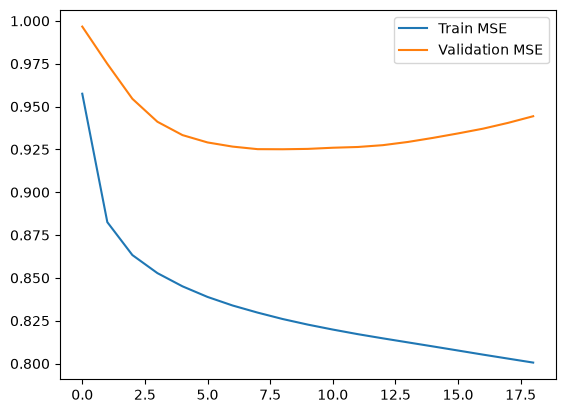

In [9]:
import matplotlib.pyplot as plt

plt.plot(history.history['mse'], label='Train MSE')
plt.plot(history.history['val_mse'], label='Validation MSE')
plt.legend()